<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   number_courses  100 non-null    int64  
 1   time_study      100 non-null    float64
 2   Marks           100 non-null    float64
 3   Course          100 non-null    object 
 4   Dates           100 non-null    object 
 5   Status          100 non-null    object 
 6   Institution     100 non-null    object 
dtypes: float64(2), int64(1), object(4)
memory usage: 5.6+ KB
Course
Statistics                 21
Data Science               19
Machine Learning           18
Mathematics                17
Artificial Intelligence    14
Computer Science           11
Name: count, dtype: int64


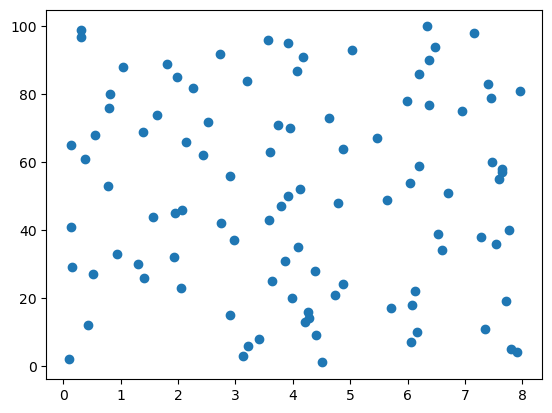

In [150]:
#Week 2 -Explanatory Data analysis
import pandas as pd
import random
import matplotlib.pyplot as plt
import seaborn as sns 
#did not continue from the same  notebook from week 1 since the data was inconsistent
#recleaning Data 
#Adding a course column to the current dataset
Student=pd.read_csv("Student_Marks.csv")
Student
#setting seed
random.seed(123)
courses = [
    "Statistics",
    "Computer Science",
    "Data Science",
    "Machine Learning",
    "Mathematics",
    "Artificial Intelligence"
]
dates=[ "2026-01-05",
    "2026-03-15",
    "2026-05-20",
    "2026-06-12",
    "2026-08-14",
    "2026-10-18"]
status=["Rejected","Accepted","Pending"]
varsity=["UJ","Wits","UP"]
Student["Course"]= [ random.choice(courses) for _ in range(len(Student))]
#application dates for the course 
Student["Dates"] =[random.choice(dates) for _ in range(len(Student))]
Student["Status"]=[random.choice(status) for _ in range(len(Student))]
Student["Institution"]=[random.choice(varsity) for _ in range(len(Student))]
#converting to real data column
Number=list(range(1,101))
#null_values
Student.isnull().sum()
#duplicates
Student.duplicated().sum()
Student
Study_Time=Student['time_study']
Marks=Student['Marks']
#Data info
Student.info()
#which course has most student
counts=Student["Course"].value_counts()
print(counts)

#scatter plots 
plt.scatter(Study_Time,Number)


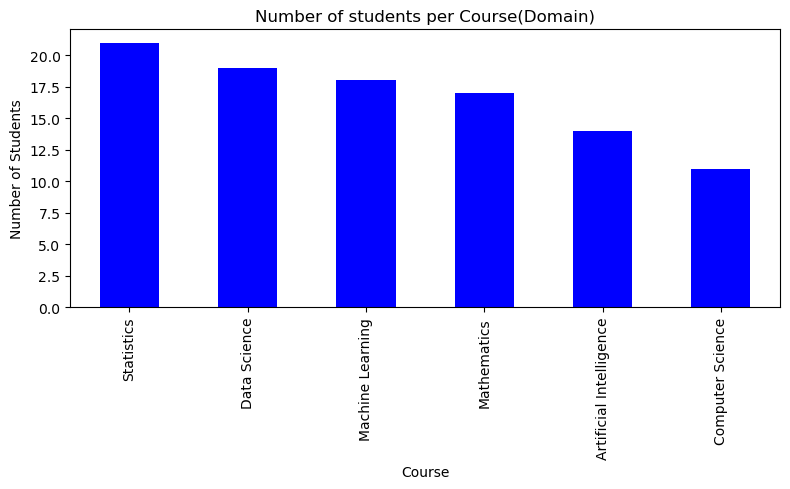

In [151]:
#barplots for the counts 
plt.figure(figsize=(8,5))
counts.plot(kind='bar',color="blue")
plt.title("Number of students per Course(Domain)")
plt.xlabel('Course')
plt.ylabel('Number of Students')
#making sure everything fits in the figure
plt.tight_layout()
#More students are doing stats almost double those in computer science
#Data science second highest followed by Machine learning


Student_month
2026-01    20
2026-03    12
2026-05    15
2026-06    19
2026-08    14
2026-10    20
Freq: M, dtype: int64


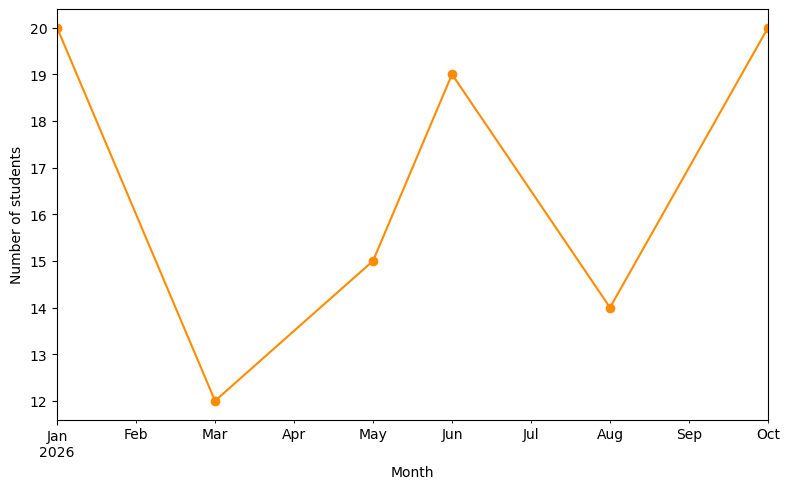

In [152]:
#Grouping students according to Months
parse_dates=Student["Dates"]
#converting to date time
Student['Dates']=pd.to_datetime(Student["Dates"])
Student['Student_month']=Student['Dates'].dt.to_period('M')
Student
#how many applications fall into each application month
monthly_trend=Student.groupby("Student_month").size()
print(monthly_trend)
#plot
plt.figure(figsize=(8,5))
#marker means put a point at each point its like the type of the plot
monthly_trend.plot(kind="line",marker='o',color="darkorange")
plt.xlabel("Month")
plt.ylabel("Number of students")
plt.tight_layout()
#more applications were received in Jan,Jun and october 
#the most peaked applications in Jan are correlating with the application start date and with another peak in Oct correlating with application closing date 



                Course                     Dates                  Institution  \
Status        Accepted Pending Rejected Accepted Pending Rejected    Accepted   
Student_month                                                                   
2026-01              8       5        7        8       5        7           8   
2026-03              5       4        3        5       4        3           5   
2026-05              5       7        3        5       7        3           5   
2026-06              6       6        7        6       6        7           6   
2026-08              6       5        3        6       5        3           6   
2026-10              6       7        7        6       7        7           6   

                                  Marks                  number_courses  \
Status        Pending Rejected Accepted Pending Rejected       Accepted   
Student_month                                                             
2026-01             5        7        8      

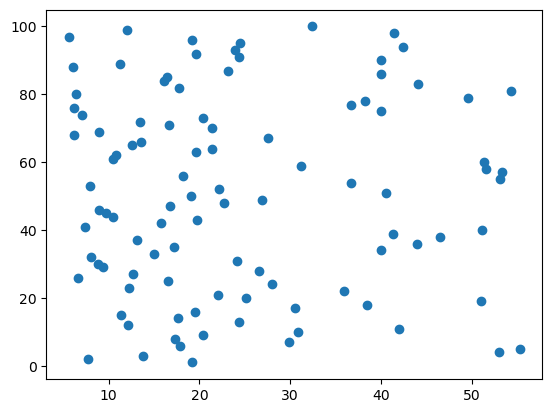

In [153]:
plt.scatter(Marks,Number)
#from plots no significant outliers hence the is no need to scale or use IQR on the data 
#Status count
Status_counts=Student["Status"].value_counts()
Status_by_domain=Student.pivot_table(Student,index="Student_month",columns="Status",aggfunc="count",fill_value=0)
print(Status_by_domain)
status_by_domain_pcf=Status_by_domain.div(Status_by_domain.sum(axis=1),axis=0)*100


In [154]:
print(status_by_domain_pcf.round(2))

                Course                     Dates                  Institution  \
Status        Accepted Pending Rejected Accepted Pending Rejected    Accepted   
Student_month                                                                   
2026-01           6.67    4.17     5.83     6.67    4.17     5.83        6.67   
2026-03           6.94    5.56     4.17     6.94    5.56     4.17        6.94   
2026-05           5.56    7.78     3.33     5.56    7.78     3.33        5.56   
2026-06           5.26    5.26     6.14     5.26    5.26     6.14        5.26   
2026-08           7.14    5.95     3.57     7.14    5.95     3.57        7.14   
2026-10           5.00    5.83     5.83     5.00    5.83     5.83        5.00   

                                  Marks                  number_courses  \
Status        Pending Rejected Accepted Pending Rejected       Accepted   
Student_month                                                             
2026-01          4.17     5.83     6.67    4.

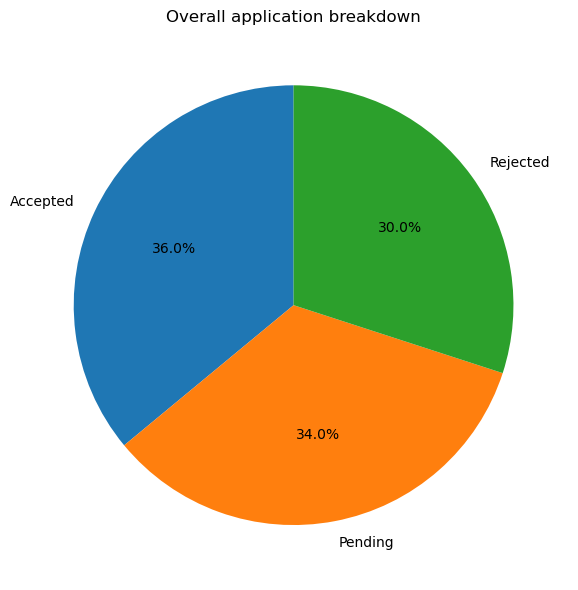

In [155]:
plt.figure(figsize=(6,6))
Status_counts.plot(kind='pie',autopct='%1.1f%%',startangle=90)
plt.title("Overall application breakdown")
plt.ylabel('')#removes the default awkward y label pie charts add
plt.tight_layout()


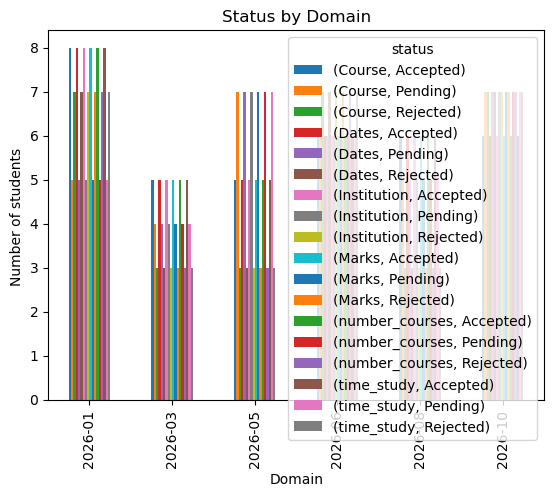

In [ ]:
#per domain grouped bar chart
Status_by_domain.plot(kind="bar")
plt.title("Status by Domain")
plt.xlabel("Domain")
plt.ylabel("Number of students ")
plt.legend(title="status")





Text(0, 0.5, 'University')

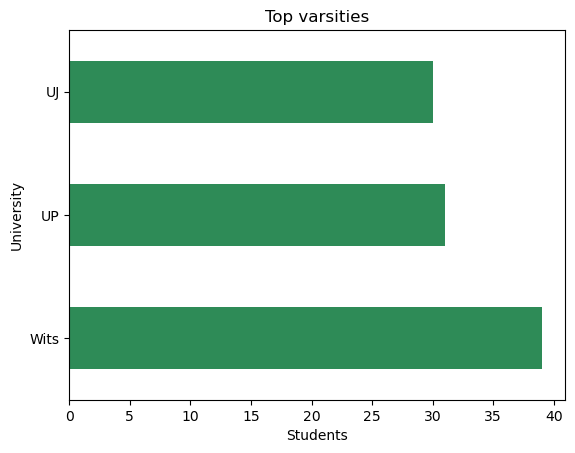

In [160]:
#Top varsities
Top=Student["Institution"].value_counts()
Top.plot(kind="barh",color="seagreen")
plt.title("Top varsities")
plt.xlabel("Students")
plt.ylabel("University")
